# Day 36/100 — IrrigationNeed | Full Reproducible Kaggle Experiment

**Kaggle input:** `/kaggle/input/datasets/loliwibu/irrigationneed-dataset` (five original sources; ZIP-extracted folder structure).  
**Primary task:** binary classification of source-recorded `irrigation` labels—not proven agronomic water demand.  
**Primary Excel:** `01_Irrigation_Dataset/.../second dataset collected.xlsx` (local audit: 3,589 rows, of which 3,588 labeled; class 0: 2,997, class 1: 591).  
**Auxiliary datasets:** Smart Irrigation Control, Environmental Sensor, Soil Moisture Motor, Irrigation Actuator & Weather. They are **audited but not mixed with the primary target**.

## Research design

1. Exact dataset provenance & file inventory; source audit and missingness.
2. Validate labels; exclude `best time` (potential leakage) and timestamps as predictors.
3. Chronological train/validation/test (70/15/15 by distinct timestamps), quarantine conflicting sensor signatures and purge exact signature overlap.
4. Dummy, Logistic Regression, Random Forest; **champion by validation macro-F1 only**.
5. **Held-out test once**; report accuracy, balanced accuracy, macro-F1, per-class metrics, failure cases.
6. Export reusable model, features, manifest, plots, reproducibility info, and lightweight result ZIP.

**Limits:** exact signature checks do not prove independence of sequential observations or farms. Source labels are recorded operator/controller decisions and should not be used as autonomous irrigation instructions. No internet access or GPU required (Kaggle CPU).

In [1]:
import os, io, json, zipfile, hashlib, warnings, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
from joblib import dump

SEED=42
np.random.seed(SEED)
OUT=Path('/kaggle/working/IrrigationNeed_Day36') if Path('/kaggle/working').exists() else Path.cwd()/'IrrigationNeed_Day36'
OUT.mkdir(parents=True,exist_ok=True)
print('Python',sys.version.split()[0], '| pandas',pd.__version__, '| scikit-learn:')
import sklearn
print(sklearn.__version__, '| output:',OUT)

Python 3.13.16 | pandas 2.3.3 | scikit-learn:
1.6.1 | output: /kaggle/working/IrrigationNeed_Day36


## Environment and execution checks

The notebook inspects installed package versions and creates an isolated output folder. The dataset mount is read-only and never modified.

In [2]:
from importlib.metadata import version, PackageNotFoundError
requirements = ['numpy', 'pandas', 'scikit-learn', 'openpyxl', 'matplotlib', 'joblib']
versions = {}
for package in requirements:
    try: versions[package] = version(package)
    except PackageNotFoundError: versions[package] = 'NOT INSTALLED'
print(json.dumps(versions, indent=2))
assert not any(v == 'NOT INSTALLED' for v in versions.values()), 'Missing core package; check Kaggle environment'

{
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scikit-learn": "1.6.1",
  "openpyxl": "3.1.5",
  "matplotlib": "3.10.0",
  "joblib": "1.6.0"
}


## 1. Dataset discovery and immutable provenance

Search for **the exact Excel basename**, either extracted or inside the uploaded ZIP. Fail clearly instead of silently substituting another dataset.

In [3]:
DATASET_ROOT=Path('/kaggle/input/datasets/loliwibu/irrigationneed-dataset')
ROOTS=[DATASET_ROOT,Path('/kaggle/input'),Path.cwd()]
print('Configured dataset root:',DATASET_ROOT, 'exists:',DATASET_ROOT.exists())
NAME='second dataset collected.xlsx'
found=[]
for root in ROOTS:
    if root.exists():
        found.extend(root.rglob(NAME))
if found:
    source=sorted(found,key=lambda p:len(str(p)))[0]
    raw=source.read_bytes()
    location=str(source)
else:
    matches=[]
    for root in ROOTS:
        if root.exists():
            for zpath in root.rglob('*.zip'):
                try:
                    with zipfile.ZipFile(zpath) as z:
                        for member in z.namelist():
                            if Path(member).name.lower()==NAME.lower():
                                matches.append((zpath,member))
                except (zipfile.BadZipFile,OSError):
                    continue
    if not matches:
        raise FileNotFoundError(f'Missing {NAME}. Attach the Day36 Kaggle dataset ZIP or its extracted files.')
    zpath,member=matches[0]
    with zipfile.ZipFile(zpath) as z:
        raw=z.read(member)
    location=f'{zpath} :: {member}'
SHA=hashlib.sha256(raw).hexdigest()
print('Source:',location,'\nSize:',len(raw),'bytes\nSHA256:',SHA)
with io.BytesIO(raw) as f:
    df_original=pd.read_excel(f,engine='openpyxl')
print('Raw shape:',df_original.shape)
display(df_original.head(4))

Configured dataset root: /kaggle/input/datasets/loliwibu/irrigationneed-dataset exists: True
Source: /kaggle/input/datasets/loliwibu/irrigationneed-dataset/01_Irrigation_Dataset/Irrigation-Dataset/second dataset collected.xlsx 
Size: 114698 bytes
SHA256: f776f34fc9c7be1eef59614dc41ddeadef6fde9dc11d908c4ec8a513d6af4d2d
Raw shape: (3589, 8)


,Time,crop type,Temperature,Humidity,Soil Moisture,Soil Tempertuer,irrigation,best time
0,2023-01-06 15:20:00,1,16.0,73.0,46.0,13,1.0,0
1,2023-01-06 15:17:00,1,16.0,73.0,46.0,13,1.0,0
2,2023-01-06 15:14:00,1,16.0,73.0,46.0,13,1.0,0
3,2023-01-06 15:11:00,1,16.0,73.0,46.0,13,1.0,0


## Source family inventory and provenance

We audit what is actually mounted (including CSV/Excel/Markdown source files); dataset licensing and provenance must be checked against original publisher documentation. Physical sensor and pump labels from auxiliary sources **are not equivalent** to the `irrigation` target.

In [4]:
from collections import Counter
import csv
MOUNT=DATASET_ROOT if DATASET_ROOT.exists() else (Path('/kaggle/input') if Path('/kaggle/input').exists() else Path.cwd())
all_files=sorted([p for p in MOUNT.rglob('*') if p.is_file()])
print('Mounted files:',len(all_files),'extension distribution:',dict(Counter(p.suffix.lower() for p in all_files)))
source_summary=[]
for p in all_files:
    rel=p.relative_to(MOUNT).as_posix()
    source_summary.append({'path':rel,'bytes':p.stat().st_size,'extension':p.suffix.lower()})
source_df=pd.DataFrame(source_summary)
display(source_df.groupby('extension',dropna=False).agg(files=('path','count'),bytes=('bytes','sum')).reset_index())
# Schema overview of source CSVs; reads header only to avoid huge raw logs
schema=[]
for p in all_files:
    if p.suffix.lower() not in {'.csv','.tsv'}: continue
    try:
        with p.open('r',encoding='utf-8-sig',errors='replace',newline='') as fp:
            head=fp.readline()
        schema.append({'file':p.relative_to(MOUNT).as_posix(),'header_preview':head[:240].strip()})
    except Exception as exc:
        schema.append({'file':str(p),'error':str(exc)})
source_schema=pd.DataFrame(schema)
display(source_schema.head(35))
source_df.to_csv(OUT/'input_file_inventory.csv',index=False)
source_schema.to_csv(OUT/'auxiliary_csv_schema_inventory.csv',index=False)

# License is NEVER guessed from file availability.
provenance={
 'primary_filename':NAME, 'primary_sha256':SHA,
 'mounted_input_root':str(MOUNT),
 'kaggle_dataset':'loliwibu/irrigationneed-dataset',
 'source_url_primary':'https://data.mendeley.com/datasets/67gkrzbwrr/1',
 'license_verified':False,
 'note':'Confirm original source licenses, attribution and permissions before any data redistribution.'
}
(OUT/'dataset_provenance_pending_verification.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')

Mounted files: 39 extension distribution: {'.xlsx': 2, '.txt': 4, '.csv': 25, '.py': 4, '.md': 3, '.json': 1}


,extension,files,bytes
0,.csv,25,481203805
1,.json,1,41642
2,.md,3,37227
3,.py,4,41098
4,.txt,4,1167327
5,.xlsx,2,167155


,file,header_preview
0,"04_Soil_Moisture_Motor/Soil Moisture, Air temp...","Soil Moisture,Temperature,Air Humidity,Pump Data"
1,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","time,value,fk_iot_node,fk_channel,is_raw,open"
2,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","value,time,is_raw,fk_iot_node"
3,"05_Irrigation_Actuator_Weather/Soil Moisture, ...",",fk_iot_node,fk_channel,nominal_flow_rate,cont..."
4,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."
5,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."
6,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."
7,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."
8,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."
9,"05_Irrigation_Actuator_Weather/Soil Moisture, ...","#,pk_measurement,value,uncalibrated_value,humi..."


493

## 2. Source audit, label validity, and banned predictors

The source label describes **recorded irrigation state/decision**. `best time` is excluded as potentially post-decision information. Dates are used for splitting but never as predictors. Do not merge data from pump-status, actuator or moisture-forecast datasets into this label.

In [5]:
df=df_original.copy()
df.columns=[str(c).strip() for c in df.columns]
print('Columns:',df.columns.tolist())
required=['Time','crop type','Temperature','Humidity','Soil Moisture','Soil Tempertuer','irrigation']
missing=[x for x in required if x not in df]
if missing: raise ValueError(f'Unexpected schema; missing: {missing}')

features=['crop type','Temperature','Humidity','Soil Moisture','Soil Tempertuer']
label_col='irrigation'
for c in features+[label_col]: df[c]=pd.to_numeric(df[c],errors='coerce')
df['_time']=pd.to_datetime(df['Time'],errors='coerce')
print('Raw missing:',df[required].isna().sum().to_dict())
print('Raw class values:',df[label_col].value_counts(dropna=False).to_dict())
print('Unparseable timestamps:',df['_time'].isna().sum())
print('Original exact duplicate records:',int(df_original.duplicated().sum()))
assert set(df[label_col].dropna().unique()).issubset({0.,1.}), 'Unexpected labels: investigate before training'
if df['_time'].isna().any():
    raise ValueError('Timestamp missing/invalid: cannot use defensible chronological split without review')
# Missing targets excluded. Missing predictors retained for imputation using training statistics only.
df=df[df[label_col].isin([0.,1.])].copy()
df[label_col]=df[label_col].astype(int)
df=df.sort_values(['_time'],kind='mergesort').reset_index(drop=True)
print('Valid labeled rows:',len(df),' | positive:',int(df[label_col].sum()))
print('Time range:',df['_time'].min(),'to',df['_time'].max())
print('Rows with missing feature:',int(df[features].isna().any(axis=1).sum()))
print('Excluded predictors: Time, best time, and every post-action variable')

Columns: ['Time', 'crop type', 'Temperature', 'Humidity', 'Soil Moisture', 'Soil Tempertuer', 'irrigation', 'best time']
Raw missing: {'Time': 0, 'crop type': 0, 'Temperature': 1, 'Humidity': 3, 'Soil Moisture': 1, 'Soil Tempertuer': 0, 'irrigation': 1}
Raw class values: {0.0: 2997, 1.0: 591, nan: 1}
Unparseable timestamps: 0
Original exact duplicate records: 0
Valid labeled rows: 3588  | positive: 591
Time range: 2022-12-30 03:56:00 to 2023-01-06 15:20:00
Rows with missing feature: 4
Excluded predictors: Time, best time, and every post-action variable


## Exploratory data analysis (EDA)

Charts show source label imbalance, missing values and feature distributions before modeling. Plots are descriptive; they are **not** used to tune using test outcomes.

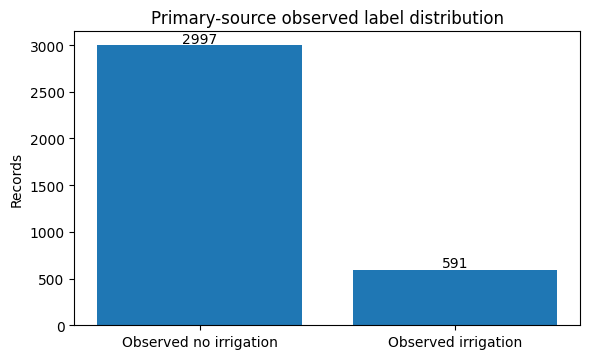

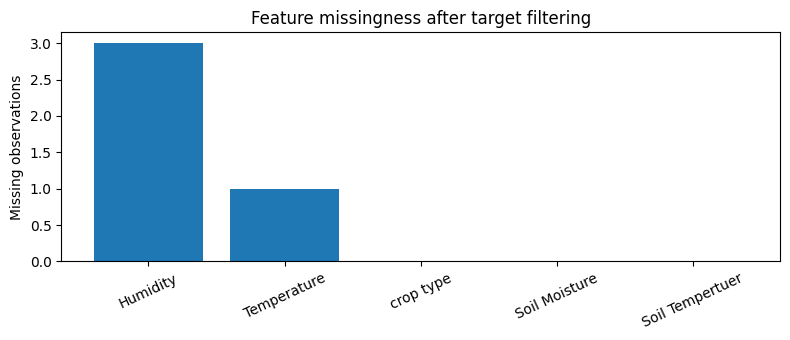

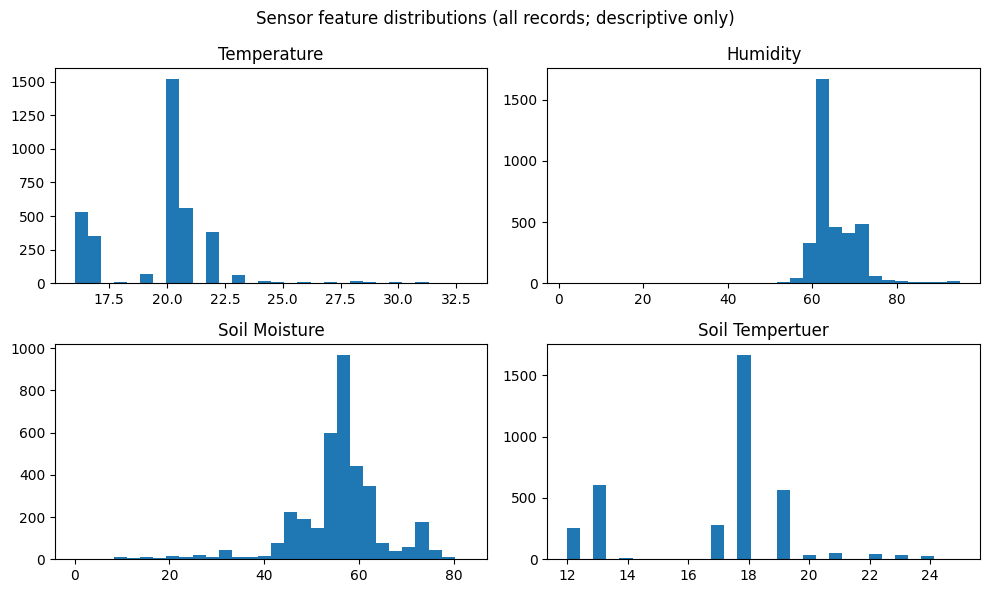

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(6,3.7))
counts=df[label_col].value_counts().reindex([0,1],fill_value=0)
ax.bar(['Observed no irrigation','Observed irrigation'],counts.values)
for i,v in enumerate(counts.values): ax.text(i,v+max(counts.values)*.01,str(int(v)),ha='center')
ax.set_ylabel('Records');ax.set_title('Primary-source observed label distribution')
fig.tight_layout();fig.savefig(OUT/'label_distribution.png',dpi=160);plt.show()

miss=df[features].isna().sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.bar(miss.index,miss.values);ax.tick_params(axis='x',rotation=25)
ax.set_ylabel('Missing observations');ax.set_title('Feature missingness after target filtering')
fig.tight_layout();fig.savefig(OUT/'missingness.png',dpi=160);plt.show()

fig,axes=plt.subplots(2,2,figsize=(10,6))
for ax,col in zip(axes.flat,[x for x in features if x!='crop type']):
    vals=df[col].dropna()
    ax.hist(vals,bins=min(30,max(5,int(np.sqrt(len(vals))))))
    ax.set_title(col)
fig.suptitle('Sensor feature distributions (all records; descriptive only)')
fig.tight_layout();fig.savefig(OUT/'sensor_distributions.png',dpi=150);plt.show()

## 3. Feature-signature leakage audit and chronological split

A signature is derived solely from predecision sensor inputs, with explicit missing-value tokens. Signatures with contradictory labels are **quarantined**, not assigned arbitrarily. Split by ordered distinct timestamps (70/15/15); later split rows whose exact signature already appeared in an earlier split are **purged**. This controls exact-signature leakage while not guaranteeing independent farms, crops, dates, or near-duplicate samples. If valid samples/classes become inadequate, stop rather than manufacture a metric.

In [7]:
def signature(row):
    vals=[]
    for v in row:
        vals.append('__MISSING__' if pd.isna(v) else format(float(v),'.10g'))
    return hashlib.sha256('|'.join(vals).encode()).hexdigest()

df['_signature']=[signature(r) for r in df[features].itertuples(index=False,name=None)]
conflicting=df.groupby('_signature')[label_col].nunique()
conflict_signatures=set(conflicting.index[conflicting>1]); n_conflicts=int(df['_signature'].isin(conflict_signatures).sum())
df_clean=df[~df['_signature'].isin(conflict_signatures)].copy()
if len(df_clean)<100: raise ValueError('Too few clean records after conflict quarantine')
unique_times=np.sort(df_clean['_time'].unique())
if len(unique_times)<20: raise ValueError('Not enough distinct timestamps for chronological split')
i=int(len(unique_times)*.70); j=int(len(unique_times)*.85)
if i<=0 or j<=i or j>=len(unique_times): raise ValueError('Invalid chronology breakpoints')
t1,t2=unique_times[i],unique_times[j]
raw_train=df_clean[df_clean['_time']<t1].copy()
raw_val=df_clean[(df_clean['_time']>=t1)&(df_clean['_time']<t2)].copy()
raw_test=df_clean[df_clean['_time']>=t2].copy()
# Exact match across chronological partitions is not allowed. Prior partitions take precedence.
train_sigs=set(raw_train['_signature'])
val=raw_val[~raw_val['_signature'].isin(train_sigs)].copy()
val_sigs=set(val['_signature'])
test=raw_test[~raw_test['_signature'].isin(train_sigs|val_sigs)].copy()
train=raw_train.copy()
purged_val=len(raw_val)-len(val); purged_test=len(raw_test)-len(test)
print('Conflicting-label rows quarantined:',n_conflicts)
print('Raw chronological split sizes:',tuple(map(len,[raw_train,raw_val,raw_test])))
print('Purged exact cross-split signatures:',{'val':purged_val,'test':purged_test})
for name,part in [('train',train),('val',val),('test',test)]:
    print(name,'n=',len(part),'labels=',part[label_col].value_counts().to_dict(),
          'period=',(str(part['_time'].min()),str(part['_time'].max())))
    if len(part)<20 or part[label_col].nunique()<2:
        raise ValueError(f'{name}: insufficient rows or class diversity after leakage purge; stop and review splits')
assert not (set(train['_signature'])&set(val['_signature']))
assert not (set(train['_signature'])&set(test['_signature']))
assert not (set(val['_signature'])&set(test['_signature']))
assert train['_time'].max()<val['_time'].min()<test['_time'].min()
Xtr,ytr=train[features],train[label_col]
Xv,yv=val[features],val[label_col]
Xte,yte=test[features],test[label_col]

Conflicting-label rows quarantined: 0
Raw chronological split sizes: (2511, 538, 539)
Purged exact cross-split signatures: {'val': 159, 'test': 22}
train n= 2511 labels= {0: 2388, 1: 123} period= ('2022-12-30 03:56:00', '2023-01-04 09:29:00')
val n= 379 labels= {1: 211, 0: 168} period= ('2023-01-04 09:47:00', '2023-01-05 12:23:00')
test n= 517 labels= {0: 285, 1: 232} period= ('2023-01-05 12:26:00', '2023-01-06 15:20:00')


## Temporal split and leakage diagnostics

Review class balance and date ranges for all three partitions. Exact-signature purging prevents identical pre-decision features across partitions, but it cannot remove near-duplicates or guarantee independence of adjacent timestamps.

,split,rows,class_0,class_1,positive_pct,start,end
0,train,2511,2388,123,4.90,2022-12-30 03:56:00,2023-01-04 09:29:00
1,validation,379,168,211,55.67,2023-01-04 09:47:00,2023-01-05 12:23:00
2,test,517,285,232,44.87,2023-01-05 12:26:00,2023-01-06 15:20:00


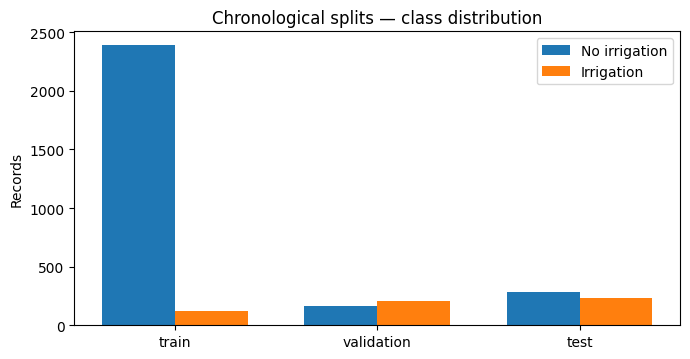

Leakage audit: {
  "quarantined_rows": 0,
  "purged_validation": 159,
  "purged_test": 22,
  "train_validation_signature_overlap": 0,
  "train_test_signature_overlap": 0,
  "validation_test_signature_overlap": 0,
  "chronological": true
}


223

In [8]:
split_report=[]
for group,part in [('train',train),('validation',val),('test',test)]:
    counts=part[label_col].value_counts().reindex([0,1],fill_value=0)
    split_report.append({'split':group,'rows':len(part),'class_0':int(counts[0]),'class_1':int(counts[1]),'positive_pct':round(float(counts[1]/len(part)*100),2),'start':str(part['_time'].min()),'end':str(part['_time'].max())})
split_table=pd.DataFrame(split_report)
display(split_table)
split_table.to_csv(OUT/'split_audit.csv',index=False)
fig,ax=plt.subplots(figsize=(7,3.7))
x=np.arange(3)
ax.bar(x-.18,split_table['class_0'],width=.36,label='No irrigation')
ax.bar(x+.18,split_table['class_1'],width=.36,label='Irrigation')
ax.set_xticks(x,split_table['split']);ax.set_ylabel('Records');ax.legend()
ax.set_title('Chronological splits — class distribution')
fig.tight_layout();fig.savefig(OUT/'split_class_balance.png',dpi=160);plt.show()
leakage_audit={'quarantined_rows':n_conflicts,'purged_validation':purged_val,'purged_test':purged_test,'train_validation_signature_overlap':len(set(train['_signature'])&set(val['_signature'])),'train_test_signature_overlap':len(set(train['_signature'])&set(test['_signature'])),'validation_test_signature_overlap':len(set(val['_signature'])&set(test['_signature'])),'chronological':bool(train['_time'].max()<val['_time'].min()<test['_time'].min())}
print('Leakage audit:',json.dumps(leakage_audit,indent=2))
(OUT/'leakage_audit.json').write_text(json.dumps(leakage_audit,indent=2),encoding='utf-8')

## 4. Training-only preprocessing and baseline model selection

Use validation macro-F1 to choose the champion. Do **not** tune models against test; test is evaluated in the next section only once. No stochastic resampling across chronological groups. Class weights address imbalance.

In [9]:
from sklearn.base import clone
models={
 'Dummy majority':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',DummyClassifier(strategy='most_frequent'))]),
 'Logistic Regression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))]),
 'Random Forest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=300,min_samples_leaf=3,class_weight='balanced_subsample',n_jobs=-1,random_state=SEED))]),
}
trained={}; rows=[]
for name,model in models.items():
    model.fit(Xtr,ytr)
    pred=model.predict(Xv)
    rows.append({'model':name,'validation_macro_f1':f1_score(yv,pred,average='macro',zero_division=0),
                 'validation_balanced_accuracy':balanced_accuracy_score(yv,pred),
                 'validation_accuracy':accuracy_score(yv,pred)})
    trained[name]=model
val_results=pd.DataFrame(rows).sort_values(['validation_macro_f1','validation_balanced_accuracy','model'],ascending=[False,False,True]).reset_index(drop=True)
display(val_results)
champion_name=str(val_results.iloc[0]['model']); champion=trained[champion_name]
print('VALIDATION-SELECTED CHAMPION:',champion_name)
val_results.to_csv(OUT/'validation_model_comparison.csv',index=False)

,model,validation_macro_f1,validation_balanced_accuracy,validation_accuracy
0,Random Forest,1.000000,1.000000,1.000000
1,Logistic Regression,0.501233,0.557874,0.601583
2,Dummy majority,0.307130,0.500000,0.443272


VALIDATION-SELECTED CHAMPION: Random Forest


## Validation comparison and selected-model behavior

The next chart uses **validation results only**. Test remains untouched until the dedicated held-out evaluation cell.

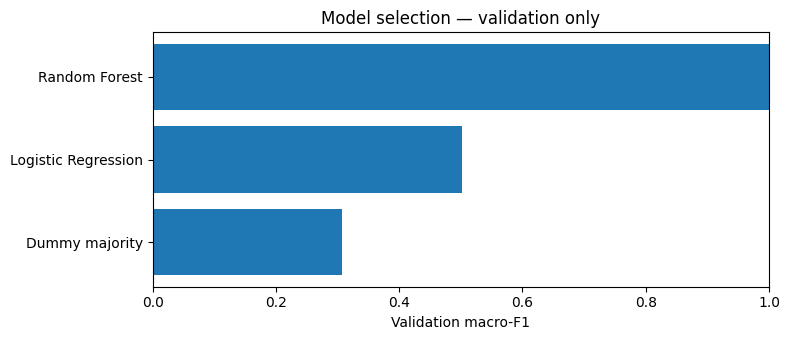

Champion: Random Forest
Validation report for selected model:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       168
           1       1.00      1.00      1.00       211

    accuracy                           1.00       379
   macro avg       1.00      1.00      1.00       379
weighted avg       1.00      1.00      1.00       379



In [10]:
fig,ax=plt.subplots(figsize=(8,3.5))
ax.barh(val_results['model'],val_results['validation_macro_f1'])
ax.set_xlim(0,1);ax.set_xlabel('Validation macro-F1')
ax.invert_yaxis();ax.set_title('Model selection — validation only')
fig.tight_layout();fig.savefig(OUT/'validation_models.png',dpi=160);plt.show()
print('Champion:',champion_name)
print('Validation report for selected model:')
print(classification_report(yv,champion.predict(Xv),labels=[0,1],zero_division=0))

## 5. One-time held-out test and honest reporting

Test is not used for feature selection, threshold optimization, hyperparameters, or model choice. Report class-wise recall because missed irrigation cases can be operationally important, without claiming irrigation recommendations are agronomically validated.

{
  "champion": "Random Forest",
  "test_count": 517,
  "test_accuracy": 1.0,
  "test_macro_f1": 1.0,
  "test_balanced_accuracy": 1.0,
  "confusion_matrix": [
    [
      285,
      0
    ],
    [
      0,
      232
    ]
  ]
}
                          precision    recall  f1-score   support

No irrigation (observed)       1.00      1.00      1.00       285
   Irrigation (observed)       1.00      1.00      1.00       232

                accuracy                           1.00       517
               macro avg       1.00      1.00      1.00       517
            weighted avg       1.00      1.00      1.00       517



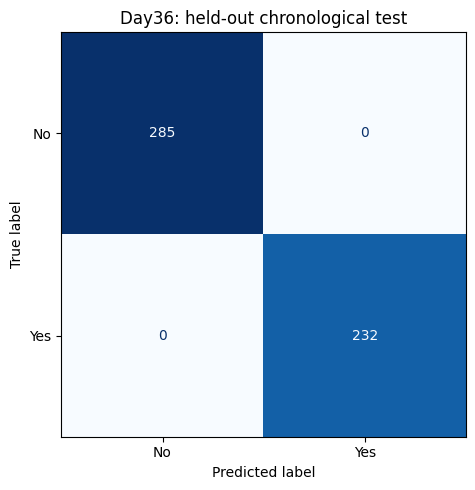

779

In [11]:
pred=champion.predict(Xte)
metrics={
 'champion':champion_name,'test_count':len(yte),'test_accuracy':float(accuracy_score(yte,pred)),
 'test_macro_f1':float(f1_score(yte,pred,average='macro',zero_division=0)),
 'test_balanced_accuracy':float(balanced_accuracy_score(yte,pred)),
 'classification_report':classification_report(yte,pred,labels=[0,1],target_names=['No irrigation (observed)','Irrigation (observed)'],output_dict=True,zero_division=0),
 'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1]).tolist(),
}
print(json.dumps({k:v for k,v in metrics.items() if k!='classification_report'},indent=2))
print(classification_report(yte,pred,labels=[0,1],target_names=['No irrigation (observed)','Irrigation (observed)'],zero_division=0))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(yte,pred,labels=[0,1],display_labels=['No','Yes'],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Day36: held-out chronological test')
fig.tight_layout();fig.savefig(OUT/'test_confusion_matrix.png',dpi=180);plt.show()
(OUT/'heldout_test_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')

## Test failure analysis (descriptive; no model re-selection)

Inspect false negatives and false positives using sensor readings and time indices. Do not change hyperparameters after looking at the held-out test.

In [12]:
error_view=test[['Time']+features+[label_col]].copy()
error_view['predicted_irrigation']=pred
error_view['error_type']=np.select(
 [(error_view[label_col]==1)&(error_view['predicted_irrigation']==0),
  (error_view[label_col]==0)&(error_view['predicted_irrigation']==1)],
 ['false_negative','false_positive'],default='correct'
)
print('Error counts:',error_view['error_type'].value_counts().to_dict())
display(error_view.loc[error_view['error_type']!='correct'].head(12))
# Export counts only; do not distribute source records in public result ZIP.
err_summary=error_view['error_type'].value_counts().rename_axis('error_type').reset_index(name='count')
err_summary.to_csv(OUT/'heldout_error_counts.csv',index=False)

Error counts: {'correct': 517}


,Time,crop type,Temperature,Humidity,Soil Moisture,Soil Tempertuer,irrigation,predicted_irrigation,error_type


## 6. Artifacts, manifest, and source limitations

**No retraining on validation or test:** exported champion is the train-fitted model selected by validation. This keeps the train-only fitting claim accurate. The source's `irrigation` labels need collection-protocol verification before deployment; do not call this a field-validated irrigation advisory system.

In [13]:
artifact=OUT/'irrigation_champion.joblib'
dump(champion,artifact)
manifest={
 'project':'IrrigationNeed Day36','task':'source-recorded irrigation classification; NOT validated crop-water necessity',
 'source_location':location,'source_sha256':SHA,'seed':SEED,'features':features,
 'class_mapping':{'0':'no irrigation (source label)','1':'irrigation (source label)'},
 'excluded_features':['Time','best time'],'split_strategy':'chronological by timestamp, purge exact signature from later splits',
 'train_count':len(train),'val_count':len(val),'test_count':len(test),
 'conflicting_label_rows_quarantined':n_conflicts,'purged_val':purged_val,'purged_test':purged_test,
 'champion_selection':'validation macro-F1 (balanced accuracy as tie-breaker)','champion':champion_name,
 'validation_macro_f1':float(val_results.iloc[0]['validation_macro_f1']),
 'test_macro_f1':metrics['test_macro_f1'],
 'limitations':['Only one source target used in training','chronological neighboring records may be highly dependent','no farm/plant-level identity split verified','target semantics not externally verified','sensor drift/domain shift untested','probability calibration not assessed'],
 'versions':{'python':sys.version.split()[0],'pandas':pd.__version__,'scikit_learn':sklearn.__version__},
}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
for name,part in [('train',train),('val',val),('test',test)]:
    part[['Time']+features+[label_col]].to_csv(OUT/f'{name}_audit_split.csv',index=False)
print('Exported files:')
for f in sorted(OUT.iterdir()): print('-',f.name,f.stat().st_size,'bytes')
print('Do not publish the raw split CSVs without verifying dataset redistribution terms.')

Exported files:
- auxiliary_csv_schema_inventory.csv 7207 bytes
- dataset_provenance_pending_verification.json 493 bytes
- experiment_manifest.json 1483 bytes
- heldout_error_counts.csv 29 bytes
- heldout_test_metrics.json 779 bytes
- input_file_inventory.csv 5310 bytes
- irrigation_champion.joblib 1317266 bytes
- label_distribution.png 34094 bytes
- leakage_audit.json 223 bytes
- missingness.png 48538 bytes
- sensor_distributions.png 64691 bytes
- split_audit.csv 246 bytes
- split_class_balance.png 32266 bytes
- test_audit_split.csv 21779 bytes
- test_confusion_matrix.png 31524 bytes
- train_audit_split.csv 105531 bytes
- val_audit_split.csv 15995 bytes
- validation_model_comparison.csv 236 bytes
- validation_models.png 29831 bytes
Do not publish the raw split CSVs without verifying dataset redistribution terms.


## Artifact integrity and Kaggle results ZIP

Only the trained model and non-sensitive aggregate reports are zipped; **raw dataset and per-row split CSVs are excluded** until source redistribution terms are verified.

In [14]:
import zipfile
artifact_hash=hashlib.sha256(artifact.read_bytes()).hexdigest()
manifest['artifact_sha256']=artifact_hash
manifest['input_root']=str(MOUNT)
manifest['auxiliary_sources_audited_only']=True
manifest['primary_target_semantics_verified']=False
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
results_zip=Path('/kaggle/working/IrrigationNeed_Day36_RESULTS.zip') if Path('/kaggle/working').exists() else OUT.parent/'IrrigationNeed_Day36_RESULTS.zip'
exclude={'train_audit_split.csv','val_audit_split.csv','test_audit_split.csv'}
with zipfile.ZipFile(results_zip,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in sorted(OUT.iterdir()):
        if f.is_file() and f.name not in exclude:
            z.write(f,f'IrrigationNeed_Day36/{f.name}')
with zipfile.ZipFile(results_zip) as z:
    bad=z.testzip()
    assert bad is None, f'CRC failure: {bad}'
print('[PASS] Result ZIP CRC')
print('Result archive:',results_zip,'bytes:',results_zip.stat().st_size)
print('Model SHA256:',artifact_hash)
print('Excluded raw row-level split files from result package:',sorted(exclude))

[PASS] Result ZIP CRC
Result archive: /kaggle/working/IrrigationNeed_Day36_RESULTS.zip bytes: 611594
Model SHA256: 835ce8cfa81402276f0795197a5eff4fab064383b583a342cff91c9b01d80593
Excluded raw row-level split files from result package: ['test_audit_split.csv', 'train_audit_split.csv', 'val_audit_split.csv']


## 7. Separate supporting-source inventory (no label mixing)

The remaining four source families (`Smart Irrigation Control`, `Environmental Sensor`, `Soil Moisture Motor`, `Irrigation Actuator Weather`) should be audited for target meaning, timestamps, units and licensing and only then used for their **own tasks** (actuation classification, sensor forecasting, etc.). This notebook intentionally does not report cross-source accuracy as if their labels were equivalent.

**Interpretation:** A successful notebook run demonstrates a reproducible classification experiment on recorded decisions, **not** a safe autonomous irrigation controller.

## How to interpret and publish the result

- **If split fails:** Do **not** replace the evaluation with a random split just to obtain a metric. Audit temporal granularity, signature overlap and independence first.
- **If test macro-F1 is low:** Report it without hiding it; examine potential temporal concept drift.
- **If test macro-F1 is high:** That does not validate a real irrigation advisory service. Input data may be serially correlated; farm/site generalization and actual crop-water need remain unverified.
- **For GitHub:** commit notebook and aggregate reports, never raw datasets or model binaries unless explicitly approved.
- **For Kaggle:** Save Version → Save & Run All; download `IrrigationNeed_Day36_RESULTS.zip` from Output.

Dataset attribution and license verification are required before public redistribution. This is an **experimental classification** model.